# Fundamentos teóricos

Esta sección responde a los seis puntos de «Fundamentos teóricos obligatorios». Cada uno se resuelve
analíticamente y después se verifica numéricamente en una celda de código. Todas las simulaciones usan
semillas fijas. Las funciones vienen del paquete `project` (`src/project`), el mismo código que se usa
en los experimentos.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project.calibration import brier_score, expected_calibration_error, fit_temperature, nll, softmax
from project.config import set_global_seed
from project.losses import bce_grad, soft_dice_grad, soft_dice_loss
from project.seg_metrics import dice_iou
from project.stats import bootstrap_ci, fmt_ci

set_global_seed(42)
rng = np.random.default_rng(42)

## 1. Relación Dice–IoU

**Notación.** Sean $A$ la predicción y $B$ la referencia (conjuntos de píxeles), $I = |A\cap B|$ y
$U = |A\cup B| = |A| + |B| - I$. Por definición

$$J = \frac{I}{U}, \qquad D = \frac{2I}{|A|+|B|}.$$

**Proposición.** $D = \dfrac{2J}{1+J}$ para el mismo par (predicción, referencia).

*Demostración.* Como $|A|+|B| = U + I$, se tiene $D = \dfrac{2I}{U+I}$. Si $U>0$, al dividir numerador y
denominador por $U$ queda $D = \dfrac{2I/U}{1 + I/U} = \dfrac{2J}{1+J}$. Si $U = 0$ (ambas máscaras
vacías), las dos métricas se fijan en 1 por convención y la identidad se mantiene. $\blacksquare$

**Monotonía.** Sea $f(J) = 2J/(1+J)$ en $[0,1]$. Entonces $f'(J) = \dfrac{2}{(1+J)^2} > 0$: $f$ es
estrictamente creciente, con $f(0)=0$ y $f(1)=1$. Además $f(J) \ge J$, porque $1+J\le 2$. En una misma
imagen, ordenar modelos por Dice o por IoU da **el mismo ranking**: $J_a > J_b \iff f(J_a) > f(J_b)$.

**Al promediar sobre imágenes el ranking puede cambiar.** Como $f''(J) = -4/(1+J)^3 < 0$, $f$ es
estrictamente cóncava. Por Jensen, $\frac1n\sum_i f(J_i) \le f\big(\frac1n \sum_i J_i\big)$, con una holgura
que crece con la dispersión de los $J_i$. Un modelo **consistente** (IoU parecido en todas las imágenes)
queda favorecido por el Dice medio frente a uno **errático** con el mismo IoU medio, o incluso con uno
mayor. Por eso $\bar D$ y $\bar J$ pueden ordenar distinto a los modelos.

**Contraejemplo.** Tomemos dos imágenes:

| | Imagen 1 | Imagen 2 | $\bar J$ | $\bar D$ |
|---|---|---|---|---|
| Modelo A (errático) | $J=0$ | $J=1$ | **0.500** | 0.500 |
| Modelo B (consistente) | $J=0.45$ | $J=0.45$ | 0.450 | **0.621** |

A gana por IoU medio y B gana por Dice medio. Abajo se construyen máscaras reales. Con píxeles discretos
el IoU de B más cercano a 0.45 resulta ≈ 0.47, y la inversión se mantiene.

max |D - 2J/(1+J)| sobre 2000 pares aleatorios = 3.03e-09
         modelo  J_img1  J_img2  IoU_medio  Dice_medio
   A (errático)   0.000   1.000      0.500        0.50
B (consistente)   0.471   0.471      0.471        0.64

=> El ranking por IoU medio (A > B) se invierte con el Dice medio (B > A).


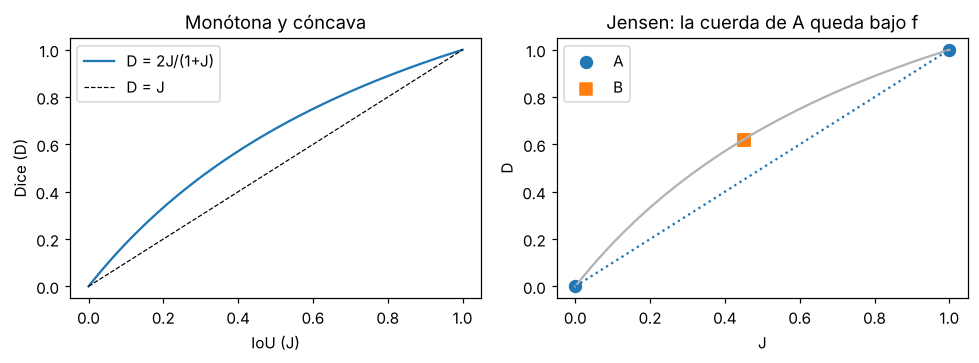

In [2]:
def square(h, w, y0, x0, s):
    m = np.zeros((h, w), bool); m[y0:y0 + s, x0:x0 + s] = True
    return m

# Verificación de la identidad con 2000 pares aleatorios de máscaras
err = []
for _ in range(2000):
    a = rng.random((32, 32)) > rng.random(); b = rng.random((32, 32)) > rng.random()
    d, j = dice_iou(a, b)
    err.append(abs(d - 2 * j / (1 + j)))
print(f"max |D - 2J/(1+J)| sobre 2000 pares aleatorios = {max(err):.2e}")

# Contraejemplo con máscaras: referencia = cuadrado de 20x20 (400 px)
gt = square(64, 64, 10, 10, 20)
pred_A = [square(64, 64, 40, 40, 20), gt.copy()]                 # J = 0 y J = 1
# Modelo B: cuadrado desplazado en diagonal con IoU ≈ 0.45 en ambas imágenes
best = min(range(1, 20), key=lambda s: abs(dice_iou(square(64, 64, 10 + s, 10 + s, 20), gt)[1] - 0.45))
pred_B = [square(64, 64, 10 + best, 10 + best, 20)] * 2
rows = []
for name, preds in (("A (errático)", pred_A), ("B (consistente)", pred_B)):
    dj = np.array([dice_iou(p, gt) for p in preds])
    rows.append(dict(modelo=name, J_img1=dj[0, 1], J_img2=dj[1, 1], IoU_medio=dj[:, 1].mean(), Dice_medio=dj[:, 0].mean()))
tab = pd.DataFrame(rows).round(3)
print(tab.to_string(index=False))
assert tab.loc[0, "IoU_medio"] > tab.loc[1, "IoU_medio"] and tab.loc[0, "Dice_medio"] < tab.loc[1, "Dice_medio"]
print("\n=> El ranking por IoU medio (A > B) se invierte con el Dice medio (B > A).")

J = np.linspace(0, 1, 200)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(J, 2 * J / (1 + J), label="D = 2J/(1+J)"); ax[0].plot(J, J, "k--", lw=0.8, label="D = J")
ax[0].set_xlabel("IoU (J)"); ax[0].set_ylabel("Dice (D)"); ax[0].legend(); ax[0].set_title("Monótona y cóncava")
ax[1].scatter([0, 1], [0, 1], s=60, label="A"); ax[1].scatter([0.45, 0.45], [2 * .45 / 1.45] * 2, s=60, marker="s", label="B")
ax[1].plot(J, 2 * J / (1 + J), color="0.7")
ax[1].plot([0, 1], [0, 1], ":", color="C0"); ax[1].set_xlabel("J"); ax[1].set_ylabel("D")
ax[1].set_title("Jensen: la cuerda de A queda bajo f"); ax[1].legend()
plt.tight_layout()

**Implicación para el proyecto.** Dice e IoU *por imagen* son redundantes, así que basta reportar uno.
Sus medias, en cambio, sí pueden discrepar. El ranking se reporta con la métrica primaria
pre-registrada (AP@[0.5:0.95], que es de instancia), y la coherencia entre órdenes se mide con la
correlación de Spearman (H2).

## 2. Gradiente de la pérdida Dice suave

Sea $p_i\in[0,1]$ la probabilidad predicha y $g_i\in\{0,1\}$ la referencia del píxel $i$. Definimos
$I = \sum_i p_i g_i$, $S = \sum_i p_i + \sum_i g_i$ y

$$\mathcal L_{\text{Dice}} = 1 - \frac{2I+\epsilon}{S+\epsilon}.$$

Como $\partial I/\partial p_i = g_i$ y $\partial S/\partial p_i = 1$, la regla del cociente da

$$\boxed{\frac{\partial \mathcal L_{\text{Dice}}}{\partial p_i} = -\,\frac{2g_i\,(S+\epsilon) - (2I+\epsilon)}{(S+\epsilon)^2}}$$

y solo puede tomar dos valores:

* **Primer plano** ($g_i=1$): $\;-\dfrac{2S - 2I + \epsilon}{(S+\epsilon)^2} < 0$, lo que empuja $p_i$ hacia 1.
* **Fondo** ($g_i=0$): $\;+\dfrac{2I+\epsilon}{(S+\epsilon)^2} > 0$, lo que empuja $p_i$ hacia 0. Es igual
  para **todos** los píxeles de fondo, sin importar si ya están bien clasificados.

**Comportamiento cuando el primer plano es mínimo.** Sean $n$ píxeles con fracción de primer plano
$\pi = m/n$.

1. *Normalización global.* El gradiente no depende de cada píxel por separado. Todo pasa por $I$ y $S$,
   que se normalizan con el tamaño del objeto. Un objeto de 20 px y uno de 2000 px pesan lo mismo en la
   pérdida, lo que contrarresta el desbalance. La entropía cruzada media, en cambio, asigna a los píxeles
   de primer plano solo una fracción $\pi$ del gradiente total.
2. *Escala $1/S$.* Si el objeto es pequeño y la predicción también ($S\to 0$), el gradiente crece como
   $1/(S+\epsilon)$ o $1/(S+\epsilon)^2$. Eso produce pasos grandes e inestables en imágenes o lotes casi
   vacíos. $\epsilon$ suaviza el problema, y por eso conviene calcular el Dice **por lote**.
3. *Imagen sin primer plano* ($m=0$): $\mathcal L = 1 - \epsilon/(\sum p + \epsilon)$. Cualquier predicción
   con $\sum p \gg \epsilon$ da pérdida ≈ 1 con gradiente casi nulo. Dice solo no penaliza bien los
   falsos positivos en imágenes vacías, y por eso suele combinarse con CE (BCE+Dice).

**Comparación.**

* **Entropía cruzada binaria** (media sobre $n$): $\partial\mathcal L/\partial p_i = \frac1n\left(-\frac{g_i}{p_i} + \frac{1-g_i}{1-p_i}\right)$.
  Es local y está bien acotada mientras $p_i \in (0,1)$. La suma de los gradientes de primer plano escala
  con $\pi$, así que si $\pi\to0$ domina el fondo y predecir «todo fondo» ya da una pérdida baja.
* **Focal** (Lin et al., 2017): $-\alpha_t(1-p_t)^\gamma\log p_t$. El factor $(1-p_t)^\gamma$ apaga los
  píxeles fáciles, que son casi todos de fondo, y concentra el gradiente en los difíciles. Ataca el
  desbalance de forma local, sin la inestabilidad de $1/S$.

**Verificación.** (a) El gradiente analítico coincide con diferencias finitas. (b) Medimos la fracción
de la norma del gradiente que viene de los píxeles de primer plano cuando $\pi$ disminuye.

In [3]:
# (a) gradiente analítico vs diferencias finitas
p = rng.random(200); g = (rng.random(200) < 0.1).astype(float); h = 1e-6
num = np.array([(soft_dice_loss(p + h * e, g) - soft_dice_loss(p - h * e, g)) / (2 * h) for e in np.eye(200)])
print(f"max |grad analítico - numérico| = {np.abs(num - soft_dice_grad(p, g)).max():.2e}")

def focal_grad(p, g, gamma=2.0, alpha=0.25, eps=1e-7):
    """Gradiente analítico de la focal binaria (media sobre píxeles) respecto a p."""
    p = np.clip(p, eps, 1 - eps); pt = np.where(g == 1, p, 1 - p); at = np.where(g == 1, alpha, 1 - alpha)
    dpt = np.where(g == 1, 1.0, -1.0)
    d = at * (gamma * (1 - pt) ** (gamma - 1) * np.log(pt) - (1 - pt) ** gamma / pt) * dpt
    return d / p.size

# (b) fracción del gradiente que viene del primer plano vs π (predicción no informativa p = 0.1 + ruido)
rows = []
n = 100_000
for pi in [0.5, 0.2, 0.05, 0.01, 0.002]:
    g = np.zeros(n); g[: int(pi * n)] = 1
    p = np.clip(0.1 + 0.05 * rng.standard_normal(n), 0.01, 0.99)
    out = dict(pi=pi)
    for name, gr in (("BCE", bce_grad(p, g)), ("Focal", focal_grad(p, g)), ("Dice", soft_dice_grad(p, g))):
        out[f"frac_grad_fg_{name}"] = np.abs(gr[g == 1]).sum() / np.abs(gr).sum()
    out["|grad_fg_Dice| por píxel"] = np.abs(soft_dice_grad(p, g)[g == 1]).mean()
    rows.append(out)
tab2 = pd.DataFrame(rows)
print(tab2.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

# Inestabilidad 1/S: magnitud del gradiente Dice en un objeto diminuto con predicción casi vacía
for m_px in [1000, 100, 10, 1]:
    g = np.zeros(10_000); g[:m_px] = 1; p = np.full(10_000, 1e-4)
    print(f"objeto de {m_px:>4d} px: max|∂L/∂p| = {np.abs(soft_dice_grad(p, g)).max():.3e}")

max |grad analítico - numérico| = 3.08e-11
   pi  frac_grad_fg_BCE  frac_grad_fg_Focal  frac_grad_fg_Dice  |grad_fg_Dice| por píxel
  0.5            0.9359              0.9935             0.9161                  3.05e-05
  0.2            0.7804              0.9736             0.7767                 6.202e-05
 0.05            0.4318              0.8881             0.6028                 0.0001284
 0.01            0.1151              0.5778             0.5193                 0.0001789
0.002           0.02702              0.2251             0.4914                 0.0001945
objeto de 1000 px: max|∂L/∂p| = 1.995e-03
objeto de  100 px: max|∂L/∂p| = 1.951e-02
objeto de   10 px: max|∂L/∂p| = 1.597e-01
objeto de    1 px: max|∂L/∂p| = 5.555e-01


**Lectura.** Con CE, la fracción del gradiente que viene del primer plano cae más o menos en proporción
a $\pi$. Con Dice se mantiene alta porque la pérdida se normaliza con el tamaño del objeto. La focal
queda en un punto intermedio. A cambio, el gradiente por píxel de Dice crece como $\sim 1/m$ en objetos
diminutos (última salida). Esto motiva la combinación **BCE + Dice** (o Tversky/focal), que se compara
en la ablación de pérdidas.

## 3. Desbalance y métricas de píxel

Sea $\pi = P(Y=1)$ la proporción de píxeles de célula. Un clasificador queda descrito por su
$\mathrm{TPR} = P(\hat Y=1\mid Y=1)$ y su $\mathrm{FPR} = P(\hat Y=1\mid Y=0)$, que **no dependen de $\pi$**.

* **Exactitud:** $\mathrm{Acc} = \pi\,\mathrm{TPR} + (1-\pi)(1-\mathrm{FPR}) \xrightarrow[\pi\to0]{} 1-\mathrm{FPR}$.
  El clasificador trivial «todo fondo» ($\mathrm{TPR}=\mathrm{FPR}=0$) obtiene $\mathrm{Acc}=1-\pi\to 1$.
* **Balanced accuracy:** $\mathrm{BA} = \tfrac12(\mathrm{TPR} + 1 - \mathrm{FPR})$ no depende de $\pi$. El
  trivial obtiene $0.5$ para cualquier $\pi$, así que es robusta frente a la prevalencia.
* **AUC-ROC** $= P(s^+ > s^-)$ compara una puntuación positiva con una negativa, ambas condicionadas a la
  clase. Tampoco depende de $\pi$. Un puntaje constante o independiente de $Y$ da $0.5$.
* **Precisión:** $\mathrm{Prec} = \dfrac{\pi\,\mathrm{TPR}}{\pi\,\mathrm{TPR} + (1-\pi)\mathrm{FPR}} \xrightarrow[\pi\to0]{} 0$
  para cualquier $\mathrm{FPR}>0$ fijo.

**Por qué PR es más informativa.** Cuando $\pi\to 0$, ROC, AUC y BA pueden ser altas (por ejemplo
$\mathrm{FPR}=1\%$ parece excelente) aunque haya muchos más falsos positivos que verdaderos. Con
$\pi = 0.001$ y $\mathrm{TPR}=0.9$ la precisión es $\approx 0.08$: unos 11 FP por cada TP. La curva PR
depende de $\pi$ a través de la precisión y muestra justo ese régimen. Su línea base (clasificador
aleatorio) es $\mathrm{AP}=\pi$, no 0.5. Para segmentación esto se traduce en un buen AUC de píxel con
fusiones o falsas detecciones, que solo las métricas de instancia o la AP-PR detectan (RQ3, H2).

**Verificación** con un modelo binormal: $s\mid Y{=}0 \sim N(0,1)$, $s\mid Y{=}1\sim N(\mu,1)$ y
$\mathrm{AUC} = \Phi(\mu/\sqrt2)$ teórico.

AUC teórico Φ(μ/√2) = 0.9214
    pi  acc_trivial  ba_trivial  auc_constante  acc_modelo  ba_modelo  auc_modelo  precision_modelo  ap_modelo  ap_aleatorio
0.5000       0.5009      0.5000         0.5000      0.8415     0.8415      0.9214            0.8411     0.9218        0.4982
0.1000       0.9009      0.5000         0.5000      0.8409     0.8413      0.9214            0.3678     0.6625        0.0988
0.0100       0.9900      0.5000         0.5000      0.8418     0.8381      0.9206            0.0505     0.2678        0.0100
0.0010       0.9991      0.5000         0.5000      0.8417     0.8421      0.9272            0.0048     0.0747        0.0009


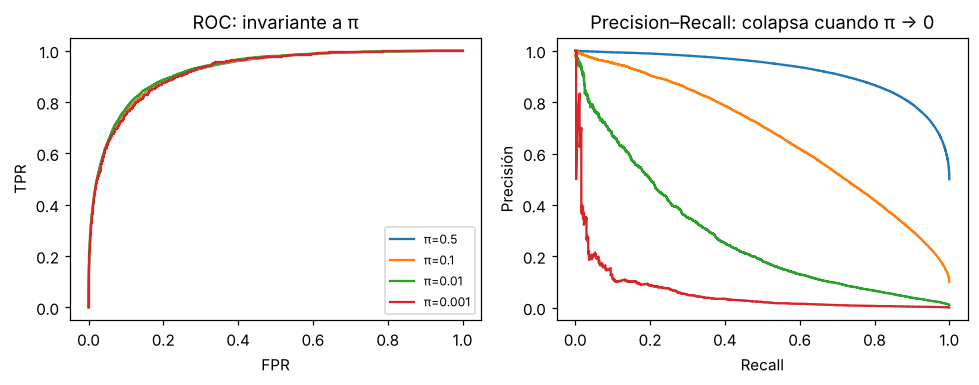

In [4]:
from scipy.stats import norm
from sklearn.metrics import average_precision_score, balanced_accuracy_score, roc_auc_score

mu, n = 2.0, 400_000
rows = []
for pi in [0.5, 0.1, 0.01, 0.001]:
    y = (rng.random(n) < pi).astype(int)
    s = rng.normal(0, 1, n) + mu * y
    yhat = (s > 1.0).astype(int)                     # umbral fijo -> TPR, FPR fijos
    triv = np.zeros(n, int)
    rows.append(dict(pi=pi,
                     acc_trivial=(triv == y).mean(), ba_trivial=balanced_accuracy_score(y, triv),
                     auc_constante=roc_auc_score(y, np.zeros(n)),
                     acc_modelo=(yhat == y).mean(), ba_modelo=balanced_accuracy_score(y, yhat),
                     auc_modelo=roc_auc_score(y, s), precision_modelo=(yhat & y).sum() / max(yhat.sum(), 1),
                     ap_modelo=average_precision_score(y, s), ap_aleatorio=average_precision_score(y, rng.random(n))))
tab3 = pd.DataFrame(rows)
print(f"AUC teórico Φ(μ/√2) = {norm.cdf(mu / np.sqrt(2)):.4f}")
print(tab3.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

from sklearn.metrics import precision_recall_curve, roc_curve
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for pi in [0.5, 0.1, 0.01, 0.001]:
    y = (rng.random(n) < pi).astype(int); s = rng.normal(0, 1, n) + mu * y
    f, t, _ = roc_curve(y, s); ax[0].plot(f, t, label=f"π={pi}")
    pr, rc, _ = precision_recall_curve(y, s); ax[1].plot(rc, pr, label=f"π={pi}")
ax[0].set_title("ROC: invariante a π"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend(fontsize=8)
ax[1].set_title("Precision–Recall: colapsa cuando π → 0"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisión")
plt.tight_layout()

La tabla confirma lo derivado. La exactitud del trivial tiende a 1. BA del trivial y AUC de un puntaje
constante quedan en 0.5. AUC y BA del modelo no cambian con $\pi$. La precisión y la AP caen a la par
con $\pi$, y la AP del clasificador aleatorio coincide con $\pi$.

## 4. Sesgo de la validación cruzada al seleccionar hiperparámetros

Sea $s_k$ el desempeño verdadero de la configuración $k$ ($k=1..K$) y $\hat s_k = s_k + e_k$ su estimación
por CV, con ruido $E[e_k]=0$. Reportar $\max_k \hat s_k$ sobre **la misma** validación es optimista:

$$E\big[\max_k \hat s_k\big] \;\ge\; \max_k E[\hat s_k] = \max_k s_k \;\ge\; s_{\hat k},$$

donde la primera desigualdad es Jensen ($\max$ es convexa) y $s_{\hat k}$ es el desempeño real de la
configuración elegida. El caso peor es aquel en que todas las configuraciones son igual de buenas y el
ruido es i.i.d. $N(0,\sigma^2)$. Ahí el sesgo es $\sigma\,E[\max_{k} Z_k]\approx \sigma\sqrt{2\ln K}$:
crece con el tamaño de la búsqueda y es mayor cuanto más pequeña y ruidosa sea la validación. La
selección «sobreajusta la validación» (Cawley & Talbot, 2010).

**Validación anidada.** El lazo **interno** elige $\hat k$ usando solo el train del pliegue externo. El
lazo **externo** evalúa el procedimiento completo (selección + reentrenamiento) en datos que nunca
intervinieron en la selección. La estimación externa es (casi) insesgada para el desempeño del
*procedimiento*. Queda un leve sesgo pesimista porque cada modelo se entrena con menos datos.

**Estimación empírica.** Usamos un modelo ligero: regresión logística con una rejilla de 30
configuraciones (C × penalización × fracción de características) y datos sintéticos donde el desempeño
verdadero se conoce gracias a un conjunto independiente de 20 000 ejemplos. Se hacen 20 réplicas y dos
escenarios: con señal débil y **sin señal** (etiquetas aleatorias, verdad = 0.5).


Escenario SIN señal (verdad = 0.5)  (20 réplicas, n = 120)
  cv_best_no_anidada   0.570 [0.554, 0.585]
  cv_anidada           0.512 [0.495, 0.528]
  verdad_holdout       0.500 [0.499, 0.502]
  sesgo_no_anidada     0.069 [0.054, 0.084]
  sesgo_anidada        0.011 [-0.005, 0.027]

Escenario con señal  (20 réplicas, n = 120)
  cv_best_no_anidada   0.645 [0.615, 0.674]
  cv_anidada           0.597 [0.572, 0.623]
  verdad_holdout       0.604 [0.572, 0.636]
  sesgo_no_anidada     0.041 [0.020, 0.062]
  sesgo_anidada        -0.007 [-0.028, 0.011]

(tiempo: 93 s)


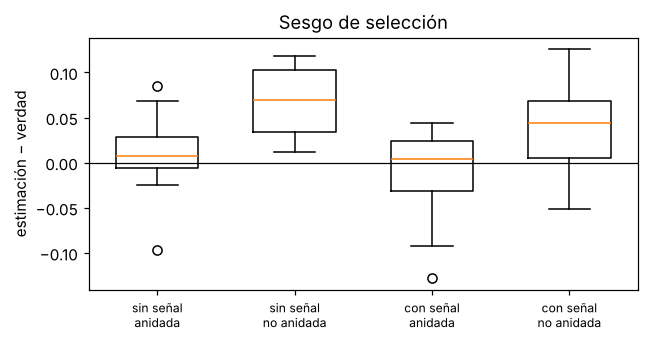

In [5]:
from sklearn.datasets import make_classification
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

GRID = [dict(C=C, k=k) for C in (0.001, 0.01, 0.1, 1, 10, 100) for k in (2, 5, 10, 25, 50)]

def make_model(prm):
    return make_pipeline(SelectKBest(f_classif, k=prm["k"]), LogisticRegression(C=prm["C"], max_iter=2000))

def experiment(seed, signal=True, n=120):
    X, y = make_classification(n + 20_000, 50, n_informative=3, n_redundant=0,
                               flip_y=0.2 if signal else 0, class_sep=0.6, random_state=seed)
    if not signal:
        y = np.random.default_rng(seed).integers(0, 2, len(y))
    Xs, ys, Xh, yh = X[:n], y[:n], X[n:], y[n:]
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    scores = [cross_val_score(make_model(p), Xs, ys, cv=cv).mean() for p in GRID]
    best = int(np.argmax(scores))
    true_best = accuracy_score(yh, make_model(GRID[best]).fit(Xs, ys).predict(Xh))
    outer = []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed + 99).split(Xs, ys):
        icv = StratifiedKFold(3, shuffle=True, random_state=seed)
        isc = [cross_val_score(make_model(p), Xs[tr], ys[tr], cv=icv).mean() for p in GRID]
        m = make_model(GRID[int(np.argmax(isc))]).fit(Xs[tr], ys[tr])
        outer.append(accuracy_score(ys[te], m.predict(Xs[te])))
    return dict(seed=seed, signal=signal, cv_best_no_anidada=scores[best], cv_anidada=np.mean(outer),
                verdad_holdout=true_best)

t0 = time.time()
res = pd.DataFrame([experiment(s, sig) for sig in (True, False) for s in range(20)])
res["sesgo_no_anidada"] = res["cv_best_no_anidada"] - res["verdad_holdout"]
res["sesgo_anidada"] = res["cv_anidada"] - res["verdad_holdout"]
for sig, d in res.groupby("signal"):
    print(f"\nEscenario {'con señal' if sig else 'SIN señal (verdad = 0.5)'}  (20 réplicas, n = 120)")
    for c in ("cv_best_no_anidada", "cv_anidada", "verdad_holdout", "sesgo_no_anidada", "sesgo_anidada"):
        print(f"  {c:<20s} {fmt_ci(*bootstrap_ci(d[c].to_numpy(), n_boot=10_000))}")
print(f"\n(tiempo: {time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(6, 3.2))
d = res.melt(id_vars="signal", value_vars=["sesgo_no_anidada", "sesgo_anidada"])
for i, (k, g) in enumerate(d.groupby(["signal", "variable"])):
    ax.boxplot(g["value"], positions=[i], widths=0.6)
ax.set_xticks(range(4)); ax.set_xticklabels(["sin señal\nanidada", "sin señal\nno anidada", "con señal\nanidada", "con señal\nno anidada"], fontsize=8)
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("estimación − verdad"); ax.set_title("Sesgo de selección")
plt.tight_layout()

**Lectura.** La CV no anidada sobrestima de forma sistemática el desempeño real del modelo elegido. Sin
señal, «encuentra» una exactitud > 0.5 donde solo hay azar. La anidada tiene un sesgo compatible con 0
(el IC lo incluye) o ligeramente pesimista. Por eso el protocolo pre-registrado exige anidada completa
para los modelos ligeros y declara el sesgo optimista residual en los pesados, que usan HPO sobre un
único split de validación.

## 5. Calibración

Sean $\hat p_i\in\Delta^{K-1}$ las probabilidades predichas, $c_i = \max_k \hat p_{ik}$ la confianza y
$\hat y_i = \arg\max_k \hat p_{ik}$.

* **ECE** (top-label, $B$ bins de confianza $\mathcal B_b$):
  $\displaystyle \mathrm{ECE} = \sum_{b=1}^{B} \frac{|\mathcal B_b|}{n}\,\Big|\mathrm{acc}(\mathcal B_b) - \mathrm{conf}(\mathcal B_b)\Big|$,
  con $\mathrm{acc}(\mathcal B_b)=\frac{1}{|\mathcal B_b|}\sum_{i\in\mathcal B_b}\mathbb 1[\hat y_i = y_i]$ y
  $\mathrm{conf}(\mathcal B_b)=\frac{1}{|\mathcal B_b|}\sum_{i\in\mathcal B_b} c_i$. Estima
  $E\big[\,|P(\hat Y = Y\mid C) - C|\,\big]$. Depende del número de bins y tiene sesgo positivo con
  pocas muestras.
* **Brier** (multiclase): $\displaystyle \mathrm{BS} = \frac1n\sum_{i=1}^n\sum_{k=1}^K(\hat p_{ik} - \mathbb 1[y_i=k])^2 \in[0,2]$.
  Es una regla de puntuación *estrictamente propia*: su esperanza se minimiza solo con las probabilidades
  verdaderas. Se descompone en confiabilidad − resolución + incertidumbre (Murphy, 1973), así que premia
  a la vez la calibración y la discriminación.

**Proposición.** Para $T>0$, $\operatorname{softmax}(z/T)$ conserva el $\arg\max$ (la exactitud no
cambia), pero la NLL sí depende de $T$.

*Demostración (argmax).* $p_k(T) = e^{z_k/T}/\sum_j e^{z_j/T}$. Para dos clases $k, j$:
$\;\dfrac{p_k(T)}{p_j(T)} = \exp\!\Big(\dfrac{z_k - z_j}{T}\Big)$, y como $T>0$ esto es $>1 \iff z_k > z_j$.
El orden de las probabilidades es el de los logits para cualquier $T>0$, luego
$\arg\max_k p_k(T) = \arg\max_k z_k$ y las predicciones $\hat y_i$ (y con ellas la exactitud, la matriz de
confusión y F1) no cambian. Si hay empates en los logits, se mantienen. $\blacksquare$

*Demostración (NLL).* Con $\beta = 1/T$:
$\;\mathrm{NLL}(\beta) = \frac1n\sum_i\Big[-\beta z_{iy_i} + \log\sum_j e^{\beta z_{ij}}\Big]$. Su derivada es

$$\frac{d\,\mathrm{NLL}}{d\beta} = \frac1n\sum_i\Big(\mathbb E_{p_i(\beta)}[z_i] - z_{iy_i}\Big),\qquad
\frac{d^2\,\mathrm{NLL}}{d\beta^2} = \frac1n\sum_i \operatorname{Var}_{p_i(\beta)}[z_i] \;\ge 0.$$

La primera derivada no es idénticamente cero salvo casos degenerados, así que la NLL varía con $T$. Es
convexa en $\beta$, con un único óptimo $\beta^*$ (temperature scaling). En los extremos,
$T\to\infty$ da la distribución uniforme ($\mathrm{NLL}\to\log K$) y $T\to 0^+$ da predicciones one-hot
($\mathrm{NLL}\to\infty$ si hay algún error). Brier y ECE también cambian con $T$, aunque la exactitud no.
$\blacksquare$

Consecuencia para **H5**: el temperature scaling, ajustado **solo en validación**, puede recuperar la
calibración de un modelo sobreconfiado sin alterar su exactitud.

T* ajustada en calibración = 3.022 (verdadera = 3)
      T  exactitud    NLL  Brier    ECE  argmax_igual
 0.5000     0.5137 2.6538 0.8141 0.3671          True
 1.0000     0.5137 1.5431 0.7098 0.2596          True
 2.0000     0.5137 1.1534 0.6210 0.1002          True
 3.0220     0.5137 1.1128 0.6061 0.0112          True
 5.0000     0.5137 1.1499 0.6252 0.0982          True
20.0000     0.5137 1.3033 0.7074 0.2238          True


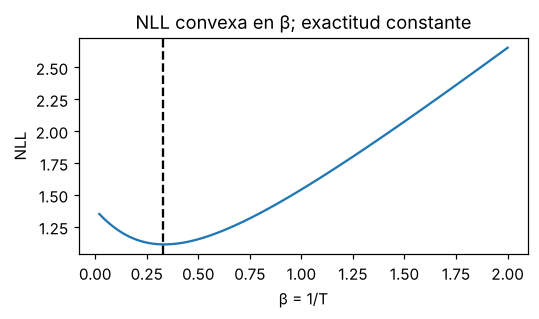

In [6]:
z = rng.normal(0, 1, (20_000, 4)); p_true = softmax(z)
y = (p_true.cumsum(1) > rng.random(len(z))[:, None]).argmax(1)    # y ~ Cat(softmax(z))
logits = 3.0 * z                                                    # modelo sobreconfiado
cal, te = slice(0, 10_000), slice(10_000, None)
T_hat = fit_temperature(logits[cal], y[cal])
rows = []
for T in [0.5, 1.0, 2.0, T_hat, 5.0, 20.0]:
    pT = softmax(logits[te] / T)
    rows.append(dict(T=round(T, 3), exactitud=(pT.argmax(1) == y[te]).mean(), NLL=nll(pT, y[te]),
                     Brier=brier_score(pT, y[te]), ECE=expected_calibration_error(pT, y[te]),
                     argmax_igual=bool((pT.argmax(1) == logits[te].argmax(1)).all())))
print(f"T* ajustada en calibración = {T_hat:.3f} (verdadera = 3)")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

betas = np.linspace(0.02, 2, 120)
nlls = [nll(softmax(logits[te] * b), y[te]) for b in betas]
fig, ax = plt.subplots(figsize=(5, 3)); ax.plot(betas, nlls); ax.axvline(1 / T_hat, ls="--", c="k")
ax.set_xlabel("β = 1/T"); ax.set_ylabel("NLL"); ax.set_title("NLL convexa en β; exactitud constante"); plt.tight_layout()
assert np.all(np.diff(np.sign(np.diff(nlls))) >= 0), "NLL(β) debería ser convexa (pendiente creciente)"

## 6. Complejidad computacional

**U-Net++** (profundidad $L$, $f$ filtros base, $f_i = f\,2^i$, entrada $H\times W$). El nodo $X^{i,j}$
trabaja a resolución $\frac{H}{2^i}\times\frac{W}{2^i}$ y aplica dos convoluciones $3\times3$. La primera
recibe $(j+1)f_i$ canales: $j$ atajos densos más la entrada sobremuestreada. Su costo es

$$\mathrm{MAC}(X^{i,j}) \approx \frac{HW}{4^i}\cdot 9\,\big[(j+1)f_i\cdot f_i + f_i^2\big] = 9\,HW\,f^2\,(j+2),$$

porque $f_i^2/4^i = f^2$: **cada nivel cuesta lo mismo por nodo**. Al sumar sobre $i=0..L$ y
$j=0..L-i$:

$$T_{\text{U-Net++}} = \Theta\!\big(HW\,f^2\,L^3\big),\qquad M_{\text{act}} = \sum_{i,j} \frac{HW}{4^i}\,2f_i = \Theta(HW\,f\,L),$$

Ambas son **lineales en el número de píxeles** para una arquitectura fija. La memoria la dominan los
$L+1$ nodos a resolución completa. U-Net solo tiene 2, así que U-Net++ necesita unas $(L+1)/2$ veces
más activaciones en el nivel superior. Ese es su costo real frente a U-Net.

**BiLSTM** (longitud $T$, dimensión de entrada $d$, $u$ unidades, 2 direcciones, $\ell$ capas). Cada paso
calcula 4 compuertas $W[x_t; h_{t-1}]$, es decir $4u(d+u)$ MAC por dirección:

$$T_{\text{BiLSTM}} = \Theta\big(\ell\,T\,u\,(d+u)\big),\qquad M = \Theta(\ell\,T\,u) \text{ (activaciones para BPTT)},$$

lineal en $T$, pero con **profundidad secuencial $\Theta(T)$**: los pasos no se paralelizan en el tiempo.

**Auto-atención** (una cabeza, dimensión $d$). Las proyecciones $Q,K,V,O$ cuestan $4Td^2$, el producto
$QK^\top$ cuesta $T^2d$ y $AV$ otros $T^2 d$:

$$T_{\text{att}} = \Theta(T d^2 + T^2 d),\qquad M_{\text{att}} = \Theta(T^2 + Td),$$

**cuadrática en $T$** cuando $T \gtrsim d$, con profundidad paralela $O(1)$ en $T$. Esto justifica el
análisis de truncamiento (`max_length`) y las latencias del transformer en la sección NLP.

**Contraste empírico.** Medimos tiempos de pasadas *forward* implementadas en NumPy (im2col + GEMM para
las convoluciones), un *proxy* de CPU que no depende de ningún framework, y ajustamos la pendiente
log–log. Se esperan pendientes ≈ 1 (U-Net++ frente a píxeles y BiLSTM frente a $T$) y ≈ 2 para la
atención con $T\gg d$. Con TensorFlow instalado, el mismo análisis se repite sobre los modelos Keras del
paquete (`build_unetpp`, `build_bilstm`) en el notebook de eficiencia.

              modelo     n       seg  MAC_teor
  U-Net++ (f=8, L=3)  4096   0.01234 6.518e+07
  U-Net++ (f=8, L=3)  9216   0.02604 1.466e+08
  U-Net++ (f=8, L=3) 16384   0.04394 2.607e+08
  U-Net++ (f=8, L=3) 36864    0.1121 5.866e+08
  U-Net++ (f=8, L=3) 65536    0.1856 1.043e+09
BiLSTM (d=100, u=64)    64   0.00265 5.374e+06
BiLSTM (d=100, u=64)   128  0.004502 1.075e+07
BiLSTM (d=100, u=64)   256  0.007862  2.15e+07
BiLSTM (d=100, u=64)   512   0.01487 4.299e+07
BiLSTM (d=100, u=64)  1024    0.0285 8.598e+07
Auto-atención (d=64)   256 0.0007442 1.258e+07
Auto-atención (d=64)   512  0.001968 4.194e+07
Auto-atención (d=64)  1024   0.00682  1.51e+08
Auto-atención (d=64)  2048   0.03808 5.704e+08
Auto-atención (d=64)  4096    0.1924 2.215e+09

Pendiente log–log (tiempo medido | MAC teóricos) respecto a n (= píxeles o T):
  Auto-atención (d=64)     medida = 2.03   teórica = 1.87
  BiLSTM (d=100, u=64)     medida = 0.86   teórica = 1.00
  U-Net++ (f=8, L=3)       medida = 0.99   teórica =

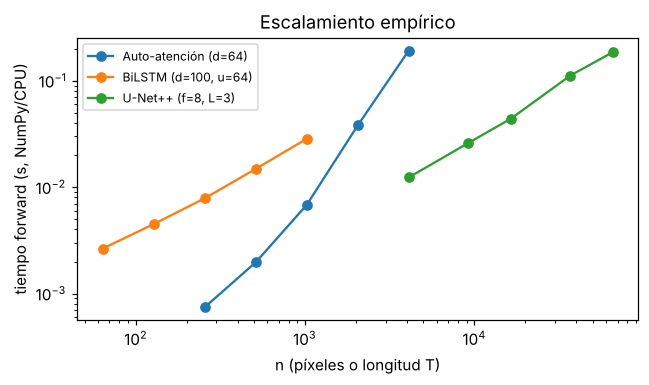

In [7]:
from project.models_seg import unetpp_complexity
from project.models_text import attention_complexity, bilstm_complexity

def conv3x3(x, w):                               # x: (H, W, Cin), w: (3, 3, Cin, Cout) — im2col + GEMM
    H, W, C = x.shape
    xp = np.pad(x, ((1, 1), (1, 1), (0, 0)))
    cols = np.lib.stride_tricks.sliding_window_view(xp, (3, 3), axis=(0, 1))   # (H, W, C, 3, 3)
    return np.maximum(cols.reshape(H * W, C * 9) @ w.transpose(2, 0, 1, 3).reshape(C * 9, -1), 0).reshape(H, W, -1)

def unetpp_forward(x, f=8, L=3, rng=np.random.default_rng(0)):
    W = {}
    def block(t, cout, key):
        if key not in W:
            W[key] = (rng.normal(0, 0.1, (3, 3, t.shape[-1], cout)).astype(np.float32),
                      rng.normal(0, 0.1, (3, 3, cout, cout)).astype(np.float32))
        return conv3x3(conv3x3(t, W[key][0]), W[key][1])
    X = {}
    for i in range(L + 1):
        src = x if i == 0 else X[i - 1, 0][::2, ::2]
        X[i, 0] = block(src, f * 2 ** i, (i, 0))
    for j in range(1, L + 1):
        for i in range(L + 1 - j):
            up = np.repeat(np.repeat(X[i + 1, j - 1], 2, 0), 2, 1)[..., : f * 2 ** i]
            X[i, j] = block(np.concatenate([X[i, k] for k in range(j)] + [up], -1), f * 2 ** i, (i, j))
    return X[0, L]

def bilstm_forward(x, u=64, rng=np.random.default_rng(0)):
    T, d = x.shape
    Wf, Wb = rng.normal(0, 0.1, (d + u, 4 * u)), rng.normal(0, 0.1, (d + u, 4 * u))
    sig = lambda v: 1 / (1 + np.exp(-v))
    outs = []
    for Wm, seq in ((Wf, x), (Wb, x[::-1])):
        h = np.zeros(u); c = np.zeros(u)
        for t in range(T):
            g = np.concatenate([seq[t], h]) @ Wm
            i_, f_, o_, c_ = sig(g[:u]), sig(g[u:2 * u]), sig(g[2 * u:3 * u]), np.tanh(g[3 * u:])
            c = f_ * c + i_ * c_; h = o_ * np.tanh(c); outs.append(h)
    return np.array(outs)

def attention_forward(x, rng=np.random.default_rng(0)):
    T, d = x.shape
    Wq, Wk, Wv, Wo = (rng.normal(0, d ** -0.5, (d, d)) for _ in range(4))
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    a = q @ k.T / np.sqrt(d); a = np.exp(a - a.max(1, keepdims=True)); a /= a.sum(1, keepdims=True)
    return (a @ v) @ Wo

def timeit(fn, reps=5):
    fn(); t = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return float(np.median(t))

res_c = []
for s in [64, 96, 128, 192, 256]:
    x = rng.random((s, s, 1)).astype(np.float32)
    res_c.append(dict(modelo="U-Net++ (f=8, L=3)", n=s * s, seg=timeit(lambda: unetpp_forward(x)),
                      MAC_teor=unetpp_complexity(s, s, 8, 3)["macs"]))
for T in [64, 128, 256, 512, 1024]:
    x = rng.random((T, 100)).astype(np.float32)
    res_c.append(dict(modelo="BiLSTM (d=100, u=64)", n=T, seg=timeit(lambda: bilstm_forward(x)),
                      MAC_teor=bilstm_complexity(T, 100, 64)["macs"]))
for T in [256, 512, 1024, 2048, 4096]:
    x = rng.random((T, 64)).astype(np.float32)
    res_c.append(dict(modelo="Auto-atención (d=64)", n=T, seg=timeit(lambda: attention_forward(x)),
                      MAC_teor=attention_complexity(T, 64)["macs"]))
rc = pd.DataFrame(res_c)
slopes = {m: (np.polyfit(np.log(g["n"]), np.log(g["seg"]), 1)[0], np.polyfit(np.log(g["n"]), np.log(g["MAC_teor"]), 1)[0])
          for m, g in rc.groupby("modelo")}
print(rc.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print("\nPendiente log–log (tiempo medido | MAC teóricos) respecto a n (= píxeles o T):")
for m, (se, st) in slopes.items():
    print(f"  {m:<24s} medida = {se:.2f}   teórica = {st:.2f}")
att = rc[rc.modelo.str.startswith("Auto")]
print("Pendiente de la atención en el tramo de T grande (2048→4096):",
      round(np.log(att.seg.iloc[-1] / att.seg.iloc[-2]) / np.log(2), 2))

fig, ax = plt.subplots(figsize=(6, 3.6))
for m, g in rc.groupby("modelo"):
    ax.loglog(g["n"], g["seg"], "o-", label=m)
ax.set_xlabel("n (píxeles o longitud T)"); ax.set_ylabel("tiempo forward (s, NumPy/CPU)"); ax.legend(fontsize=8)
ax.set_title("Escalamiento empírico"); plt.tight_layout()

**Lectura.** Las pendientes medidas coinciden con los órdenes derivados. U-Net++ y BiLSTM escalan
aproximadamente de forma lineal (≈ 1.0 y ≈ 0.9). La pendiente de BiLSTM queda algo por debajo de 1 por
los costos fijos del lazo en Python cuando $T$ es pequeño. En U-Net++, con imágenes mayores que las
medidas, las matrices im2col dejan de caber en la caché y la pendiente aparente supera 1: el cuello de
botella pasa a ser la memoria, no las MAC, aunque estas siguen siendo lineales. En la atención, la pendiente se acerca a 2 cuando el término $T^2d$ domina sobre $Td^2$
(aquí $T \gg d = 64$). Para el
transformer esto implica que la latencia y la memoria crecen rápido con `max_length`. Para U-Net++, que
conviene inferir en resolución nativa con *tiling* en lugar de agrandar la imagen. Los valores absolutos
corresponden a NumPy en CPU, no a GPU. Lo que se contrasta es el **orden** de crecimiento, no las
constantes.